# **Twitter Sentiment Analysis**

## **1. Data Collection and Preprocessing**

### **1.1 Load the Sentiment140 dataset**

In [2]:
import pandas as pd
import numpy as np

In [3]:
# Define column names
columns = [
    "sentiment",
    "id",
    "date",
    "query",
    "user",
    "text"
]

# Load the dataset
df = pd.read_csv(
    "../data/training.1600000.processed.noemoticon.csv",
    encoding="latin-1",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1600000, 6)


,sentiment,id,date,query,user,text
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."


### **1.2 Explore the dataset**

In [4]:
# Check dataset information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check sentiment distribution
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 6 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   sentiment  1600000 non-null  int64
 1   id         1600000 non-null  int64
 2   date       1600000 non-null  str  
 3   query      1600000 non-null  str  
 4   user       1600000 non-null  str  
 5   text       1600000 non-null  str  
dtypes: int64(2), str(4)
memory usage: 73.2 MB

Missing values:
sentiment    0
id           0
date         0
query        0
user         0
text         0
dtype: int64

Sentiment distribution:
sentiment
0    800000
4    800000
Name: count, dtype: int64


### **1.3 Clean and tokenize the tweets**

In [5]:
import re
from nltk.tokenize import TweetTokenizer

# Initialize tokenizer
tokenizer = TweetTokenizer()

# Define cleaning function
def clean_tweet(text):

    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenize text
    tokens = tokenizer.tokenize(text)

    return tokens


# Select a balanced sample of 20,000 tweets
df_sample = pd.concat([
    df[df["sentiment"] == 0].sample(
        n=10000, random_state=42
    ),
    df[df["sentiment"] == 4].sample(
        n=10000, random_state=42
    )
]).sample(frac=1, random_state=42).copy()

# Apply preprocessing
df_sample["tokens"] = df_sample["text"].apply(clean_tweet)

# Convert tokens back into cleaned text
df_sample["cleaned_text"] = df_sample["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Display results
display(
    df_sample[
        ["sentiment", "text", "cleaned_text", "tokens"]
    ].head()
)

,sentiment,text,cleaned_text,tokens
1067790,4,@DawnRichard THANKS LUV...KEEP THE GRIND GOING...,thanks luv keep the grind going like i know u ...,"[thanks, luv, keep, the, grind, going, like, i..."
395233,0,I feel like watching The Life Aquatic. But I d...,i feel like watching the life aquatic but i do...,"[i, feel, like, watching, the, life, aquatic, ..."
717155,0,So aparentally early this morning Erol died of...,so aparentally early this morning erol died of...,"[so, aparentally, early, this, morning, erol, ..."
72562,0,"Chopchop, get dressed! Getting ready for work",chopchop get dressed getting ready for work,"[chopchop, get, dressed, getting, ready, for, ..."
855824,4,@misshaleymae You know it baby ! x,you know it baby x,"[you, know, it, baby, x]"


In [ ]:
# Verify the cleaned tweets

print("Original tweet:")
print(df_sample["text"].iloc[0])

print("\nCleaned tweet:")
print(df_sample["cleaned_text"].iloc[0])

print("\nTokens:")
print(df_sample["tokens"].iloc[0])

Original tweet:
@DawnRichard THANKS LUV...KEEP THE GRIND GOING (LIKE I KNOW U WILL)...STAY POSITIVE (LIKE U ALWAYS DO) AND PRAY 2 THE NIPPLE GODS! 

Cleaned tweet:
thanks luv keep the grind going like i know u will stay positive like u always do and pray the nipple gods

Tokens:
['thanks', 'luv', 'keep', 'the', 'grind', 'going', 'like', 'i', 'know', 'u', 'will', 'stay', 'positive', 'like', 'u', 'always', 'do', 'and', 'pray', 'the', 'nipple', 'gods']


In [ ]:
# Save cleaned dataset

df_sample.to_csv(
    "../data/sentiment140_cleaned.csv",
    index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## **2. Model Training**

### **2.1 Prepare the features and target variable**

In [8]:
# Prepare features and target
X = df_sample["cleaned_text"]

# Convert sentiment labels: 0 = Negative, 1 = Positive
y = df_sample["sentiment"].map({
    0: 0,
    4: 1})

# Check target distribution
print(y.value_counts())

sentiment
1    10000
0    10000
Name: count, dtype: int64


### **2.2 Split the dataset into training and validation sets**

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 16000
Validation samples: 4000


### **2.3 Convert tweets into numerical features using TF-IDF**

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2))

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation data
X_val_tfidf = tfidf.transform(X_val)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)

Training TF-IDF shape: (16000, 10000)
Validation TF-IDF shape: (4000, 10000)


### **2.4 Train the Logistic Regression model**

In [11]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
model = LogisticRegression(
    max_iter=1000,
    random_state=42)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### **2.5 Evaluate the model on the validation dataset**

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix)

# Predict validation sentiments
y_pred = model.predict(X_val_tfidf)

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_pred)
precision = precision_score(y_val, y_pred)
recall = recall_score(y_val, y_pred)
f1 = f1_score(y_val, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_pred,
    target_names=["Negative", "Positive"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

Model Evaluation Results
------------------------
Accuracy: 0.7708
Precision: 0.7687
Recall: 0.7745
F1-score: 0.7716

Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.77      0.77      2000
    Positive       0.77      0.77      0.77      2000

    accuracy                           0.77      4000
   macro avg       0.77      0.77      0.77      4000
weighted avg       0.77      0.77      0.77      4000


Confusion Matrix:
[[1534  466]
 [ 451 1549]]


### **2.6 Visualize the confusion matrix**

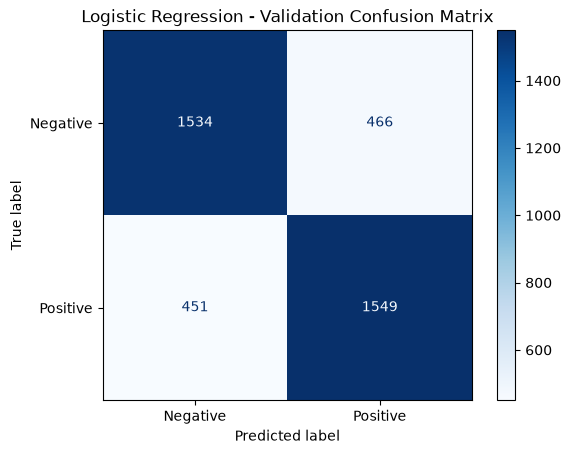

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Logistic Regression - Validation Confusion Matrix")
plt.show()

### **2.7 Save the trained model**

In [14]:
import joblib

# Save model
joblib.dump(model, "../models/logistic_regression_model.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


## **3. API Development and Containerization**